<h2> Infrastructure </h2>

In [ ]:
# Thermal Controller Board Level Prototype
# By Shawn Newman

In [ ]:
# Tips:  
  
# VSCode:
#    * Outline button is in the row of buttons right above this pane. Much easier navigation. You may need to vertically expand it
#    * Click on the blue bar to the left of a cell to hide it. Also works on outputs
#    * Right click on any function call and select "Go to Definition" to jump to the actual function
#
# Jupyter Notebook:
#    * [View->Table of contents] for the outline
#    * You can click the arrow to the left of headings to collapse/expand their section
#
# Structure:
#    * The first code cell "Initialize All" should run every other cell that exclusively defines functions and imports libraries.
#    * The headings in the outline with an asterisk are the ones that actually use those functions, 
#      constants, and libraries to do things. You'll manually run those.
#    * Don't click the little "init" buttons in the bottom left of cells, it erases the tag that "Initialize All" uses to filter.
#
# Misc:
#    * [ctrl+Enter] runs a cell
#    * Select multiple lines of code, then press [ctrl+/] to comment or uncomment all 
#      (I just discovered this a couple months ago and am mad about it)

<h3>* Initialize All Functions & Libraries</h3>

In [42]:
# Turn on File->'Auto Save' if you want to use this. It reads cell data from disk.
# This runs every cell in here with the tag "init". Library imports, function definitions, constants, etc.
# Saves a lot of time. Works well as a redundancy.

import nbformat # Library for manipulating notebooks

def execute_cells_by_tag(group_tag, quiet=True):
    filepath = globals()['__vsc_ipynb_file__'] # Returns path to this file
    if (quiet==False): print(filepath)
    nb = nbformat.read(open(filepath, 'r', encoding='utf-8'), as_version=4) # Saves this notebook as JSON
    ip = get_ipython()                                                      # Gets the "global InteractiveShell instance"
    if (quiet==False): print(ip)
    for cell_number in range(len(nb.cells)):
        cell=nb.cells[cell_number]
        #print(cell)
        if 'tags' in cell.metadata:
            if group_tag in cell.metadata.tags:
                ip.run_cell(cell.source)
                if (quiet==False): print(f"Ran Cell {cell_number}")

execute_cells_by_tag('init') 
print("") # Newline

Imported Libraries
ICASL is loaded!
Initialized Constants:
RUN_TIME = 540
NUM_MEASUREMENTS_BEFORE_HEAT = 20
GLOBAL_VSET = -1.1
GLOBAL_TEMPS = [-25, -28, -30, -40, -50, -75, -100]
Initialized 'Establish Connection'
Initialized Equipment Interfacing Functions
Initialized Plotting Default Styling
Initialized Plotting Functions
Initialized Full Procedure



In [ ]:
import pyvisa                            # Instrument communication
import time                              # Handle time-related tasks (e.g., delays)
import matplotlib.pyplot as plt          # Plotting graphs and visualizing data
from matplotlib.ticker import LogLocator # Used for ticks in logarithmic plots
import numpy as np                       # Numerical operations, particularly with arrays
import pandas as pd                      # Data manipulation and analysis, csv files
import os                                # Interact with the operating system, such as handling file paths
import importlib.util                    # Used to load python files more dynamically (ICASL.py)
import winsound                          # Custom beeps/noises

print("Imported Libraries")

Imported Libraries


In [ ]:
# Imports ICASL from this directory

# import ICASL.py
# ICASL.test()

In [25]:
# Loads ICASL.py from a higher directory
# This file contains functions written by us that can be called with "ICASL.example_function_name"
quiet=True
current_dir = "."
target_file = "ICASL.py"
target_name = "ICASL"
while True:
    if not quiet: print(current_dir)
    # Check if ICASL is in the current directory
    ICASL_path = os.path.join(current_dir, target_file)
    if not quiet: print(ICASL_path)
    if os.path.isfile(ICASL_path):
        # Loads ICASL.py
        spec = importlib.util.spec_from_file_location(target_name, ICASL_path)
        ICASL = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(ICASL)
        break
    else:
        # Move one level up
        parent_dir = os.path.join(current_dir, "..")
        if not quiet: print(parent_dir)
        if current_dir == parent_dir:  # Reached the root directory
            raise ValueError("ICASL.py not found")
        else:
            current_dir = parent_dir
ICASL.test()

ICASL is loaded!


<h3> Constants </h3>

In [ ]:
print("Initialized Constants:")

DEVICE_NAME = "Prototype_Board" # Used for labelling.
SET_PRECISION = .6  # How close the probe's temperature needs to get to the SET value before soak time begins (in Celsius)
SETTLING_TIME = .15 # Default wait time between setting values and measuring. Varies depending on the circuit -- can make the tests take much longer. Not used here.
SOAK_TIME = 480     # How long to soak at temperature (in seconds). Blalock recommended 5 minutes. Longer now because of how essential thermal precision is.
COLD_START_TIME = 10
LOG = True

NUM_MEASUREMENTS_BEFORE_HEAT = 20   # How many measurements before heat is turned on. MEASURE_TIME is ~1.4s (for all instrument data to be transmitted)
RUN_TIME = 60 + 480                 # How long heat is left on and off (each, not total)

VSET_ROOM_TEMP = -1.1   #  25C
VSET_FZTC = -0.924      # -28C

GLOBAL_VSET = VSET_ROOM_TEMP                        # Used within tests -- override its value when needed
GLOBAL_TEMPS = [-25, -28, -30, -40, -50, -75, -100] # Not used within tests -- here for you to copy it and then adjust/work with those copies

print(f"RUN_TIME = {RUN_TIME}")
print(f"NUM_MEASUREMENTS_BEFORE_HEAT = {NUM_MEASUREMENTS_BEFORE_HEAT}")
print(f"GLOBAL_VSET = {GLOBAL_VSET}")
print(f"GLOBAL_TEMPS = {GLOBAL_TEMPS}")


Initialized Constants:
RUN_TIME = 540
NUM_MEASUREMENTS_BEFORE_HEAT = 20
GLOBAL_VSET = -1.1
GLOBAL_TEMPS = [-25, -28, -30, -40, -50, -75, -100]


### Data Format

In [ ]:
# This clarifies how csv files are saved and loaded -- called by tests & plots. Leads to less bugs with mismatched file names

# "save_dir" is the temperature directory
def store_data(df, save_dir, VSET, test_name):
    df.to_csv(os.path.join(save_dir, f'{test_name}__VSET={VSET}.csv'), index=False)

# "load_dir" is NOT the temperature directory -- it'll be one above it. 
def load_data(load_dir, amb_T, VSET, test_name):
    df = ICASL.read_csv(os.path.join(load_dir, f"temp={amb_T}", f"{test_name}__VSET={VSET}.csv"))
    df = ICASL.fix_dataframe(df)
    return df

<h2> Equipment </h2>

In [5]:
# Enable full pyvisa logging
pyvisa.log_to_screen()

In [6]:
# Disable full pyvisa logging
import logging
pyvisa.log_to_screen(level=logging.INFO)

In [ ]:
def establish_connection(address, query):
    instrument = rm.open_resource(address)   # Open a connection to the instrument with the address and assign it to SM_VIN
    instrument.read_termination = '\n'       # Set the read termination character to a newline. This tells pyvisa when to consider a message as complete when reading from the instrument.
    instrument.write_termination = '\n'      # Set the write termination character to a newline. This ensures that each command sent to the instrument is properly terminated.
    instrument.baud_rate = 9600              # Set the baud rate for serial communication to 9600. This is the speed at which data is transmitted over the serial connection.
    print(instrument)                        # Print the resource object to display its properties
    if query != "NONE":
        print(instrument.query(query))           # Send the query to the instrument and print its response. This command usually asks the instrument to identify itself (e.g., manufacturer, model number).
    return instrument

print("Initialized 'Establish Connection'")

Initialized 'Establish Connection'


<h3>* Connect Equipment </h3>

Equipment not automated for this test (manually turned on and set beforehand):
- Analog PS: +-5V, 500 mA current limit for both channels
- Oscillator PS: 3.3V, 10 mA current limit
- Triangle Wave WG: 2V max, 2V min, 1000 Hz frequency, 50% shape (true triangle)
- Frequency Counter -- more accurate measurements, but can't interface with this one.

In [2]:
# Keep each device's voltages/currents in their names
# For a device with multiple channels, list each channel's voltage/current in order
# Everything needs to be powered on before plugging anything into the DUT (Device Under Test). Even the temp chamber and USB connections!

rm = pyvisa.ResourceManager() 

MM_VRTD = establish_connection('USB0::10893::769::MY57508173::0::INSTR', '*IDN?')
MM_V1mA = establish_connection('USB0::10893::257::MY57508183::0::INSTR', '*IDN?')
WG_VSET = establish_connection('GPIB6::10::INSTR', '*IDN?')
CHAMBER = establish_connection('GPIB6::6::INSTR', 'STATUS?')
OSC_oscillator = establish_connection('USB0::2391::6070::MY56310504::INSTR', '*IDN?')
OSC_tri_pulse = establish_connection('USB0::2391::6038::MY57231553::INSTR', '*IDN?')
PS_heat = establish_connection('USB0::0xFFFF::0x9130::602360010727720104::INSTR', '*IDN?')

USBInstrument at USB0::10893::769::MY57508173::0::INSTR
Keysight Technologies,34465A,MY57508173,A.02.17-02.40-02.17-00.52-04-01
USBInstrument at USB0::10893::257::MY57508183::0::INSTR
Keysight Technologies,34465A,MY57508183,A.02.17-02.40-02.17-00.52-04-01
GPIBInstrument at GPIB6::10::INSTR
Agilent Technologies,33522B,MY57890777,4.00-1.19-2.00-58-00
GPIBInstrument at GPIB6::6::INSTR
YNNNYNNNNNNNNNNNNN0
USBInstrument at USB0::2391::6070::MY56310504::0::INSTR
AGILENT TECHNOLOGIES,MSO-X 4024A,MY56310504,04.08.2016071800
USBInstrument at USB0::2391::6038::MY57231553::0::INSTR
AGILENT TECHNOLOGIES,MSO-X 2024A,MY57231553,02.42.2017032900
USBInstrument at USB0::0xFFFF::0x9130::602360010727720104::0::INSTR
B&K Precision, 9131B, 602360010727720104, 1.10-1.04


In [6]:
#rm = pyvisa.ResourceManager() 
rm.list_resources() # List all available resources (e.g., connected instruments) managed by pyvisa

('USB0::0x2A8D::0x0301::MY57508173::INSTR',
 'USB0::0x0957::0x17B6::MY56310504::INSTR',
 'USB0::0x2A8D::0x0101::MY57508183::INSTR',
 'USB0::0x0957::0x1796::MY57231553::INSTR',
 'USB0::0xFFFF::0x9130::602360010727720104::INSTR',
 'GPIB6::6::INSTR',
 'GPIB6::10::INSTR',
 'GPIB6::20::INSTR',
 'USB0::0x0957::0x0607::MY45002108::0::INSTR',
 'USB0::0x0957::0x1796::MY57231548::0::INSTR',
 'USB0::0x0957::0x2C07::MY57890777::0::INSTR',
 'USB0::0x0957::0x5707::MY53802060::0::INSTR',
 'USB0::0x2A8D::0x0101::MY54505624::0::INSTR',
 'USB0::0x2A8D::0x0301::7&13599196&0&0000::0::INSTR')

In [ ]:
# This didn't work -- Can't connect Keithley 2231A power supplies. Need a special adapter for any cables.
test = establish_connection('ASRL3::INSTR', 'NONE')
test.write(":SYSTem:REMote")
test.query("*IDN?")

SerialInstrument at ASRL3::INSTR


VisaIOError: VI_ERROR_TMO (-1073807339): Timeout expired before operation completed.

Equipment Info

To find IDs:
- Waveform Generators: System -> I/O Settings -> USB 
- Multimeters: Utility -> I/O Config -> USB Settings -> Show USB ID
- SourceMeters:
- Sun Chamber: 'GPIB6::6::INSTR'

Temperature Chamber Status Codes:

Y = power is on\
2: Y = command error last command\
3: Y = time out LED is on\
4: Y = waiting for timeout\
5: Y = heat output is enabled\
6: Y = cool output is enabled\
7: Y = valid set temperature\
8: Y = deviation limit exceeded\
9: Y = currently ramping\
10: Y = chamber temp < lower limit\
11: Y = chamber temp > upper limit\
12: Y = waiting at a BKPNT\
13: Y = in LP run mode\
14: Y = in LP remote store mode\
15: Y = in local edit LP mode\
16: Y = waiting to run LP at TOD\
17: Y = GPIB bus timeout\
18: Y = in local keyboard lockout mode\
19: 0 = system Self Test was OK\
1 = Battery RAM error found (check default settings)\
2 = EE RAM error found (check probe calibration)\
3 = ROM error found (call factory)\

<h3> Equipment Functions </h3>

In [ ]:
####### Temperature Chamber #######

def chamber_init(RATE=20):
    CHAMBER.write("ON")                  # Also turns on heat and cool (unless configured otherwise)
    CHAMBER.write("RATE={RATE}") # Sets the speed at which the chamber will ramp to change temp
    CHAMBER.write("WAIT=FOREV")          # Sets the time that the chamber will wait once the desired temperature is reached before moving to next temp. We don't use this.
    CHAMBER.write("HON")                 # Turns heat on (just in case)
    CHAMBER.write("CON")                 # Turns cool on (just in case)
    CHAMBER.write("PIDA=3")              # Switches to monitoring user probe when setting temperature (DUT will reach temperature, not the top of the chamber)
    time.sleep(1) 
    #print(CHAMBER.query("RATE?"))
    #print(CHAMBER.query("WAIT?"))

# TODO: Figure out when SCPI needs leading colons (never?)
# TODO: Switch to using full names for SCPI commands
# TODO Oscilloscope init?

# Initializations

####### MM ####### -- Keysight 34454A


def MM_init(MM):
    MM.write(":CONF:VOLT:DC")
    MM.write("VOLT:DC:RANG 10")
    MM.write("VOLT:NPLC 1")

def MM_local(MM):
    MM.write("SYSTEM:LOCAL")

# TODO: MM_reset() ?

####### WG ####### -- Keysight 33500B

# IMPORTANT: This will set the WG's output value to 0! (But leave output on, for some reason)
def WG_init(WG):
    WG.write("OUTP1:LOAD DEF")          # Sets the output load to infinite so no impedance matching is necessary
    WG.write("SOUR1:APPL:DC")           # Sets the Waveform generator to output a DC voltage

def WG_on(WG, channel, val):
    # Only channel 1 was used for this test, for VSET
    # We had a second, separate waveform generator output a triangle wave, manually set.
    # A third waveform generator applied a 10 MHz reference signal to the oscilloscope so it could obtain higher precision.
    if (channel != 1 and channel != 2):
        print("Invalid channel")
        return -1
    WG.write(f"SOUR{channel}:APPL:DC DEF, DEF, {val}")
    WG.write(f"OUTP{channel}:STAT 1")

def WG_off(WG, channel):
    if (channel != 1 and channel != 2):
        print("Invalid channel")
        return -1
    WG.write(f"SOUR{channel}:APPL:DC DEF, DEF, 0")
    WG.write(f"OUTP{channel}:STAT 0")

####### OSC ####### -- Keysight InfiniiVision MSOX2024 and MSOX4024

def OSC_measure_freq(OSC, channel):
    # You can't measure the counter if it's already on screen, for some reason.
    OSC.write(":MEASure:CLEar")
    return OSC.query(f":MEASURE:COUNTER? CHANNEL{channel}")

def OSC_measure_duty(OSC, channel):
    return OSC.query(f":MEASURE:DUTY? CHANNEL{channel}")

def OSC_measure_peak_to_peak(OSC, channel):
    return OSC.query(f":MEASURE:VPP? CHANNEL{channel}")

def OSC_measure_std(OSC, channel):
    return OSC.query(f":MEASURE:SDEVIATION? CHANNEL{channel}")

def OSC_set_measurements(OSC, channel):
    OSC.write(f":MEASURE:COUNTER CHANNEL{channel}")
    OSC.write(f":MEASURE:FREQUENCY CHANNEL{channel}")
    OSC.write(f":MEASURE:VPP CHANNEL{channel}")
    OSC.write(f":MEASURE:DUTY CHANNEL{channel}")
    OSC.write(":MEASURE:STATISTICS")
    OSC.write(":MEASURE:STATISTICS:DISPLAY 1")

####### PS ####### -- BX Precision 9131B

def PS_turn_on(PS):
    PS.write("OUTPUT ON")

def PS_turn_off(PS):
    PS.write("OUTPUT OFF")

def PS_set_channel(PS, channel, voltage, current_limit):
    PS.write(f"SOURCE:APPLY CH{channel},{voltage},{current_limit}")

def PS_read_all_current(PS):
    return PS.query("MEASURE:CURRENT:ALL?")

def PS_check(PS):
    PS_status = PS.query(f"OUTPUT?")
    #print(PS_status)
    print(f"Power supply is currently {"ON" if (PS_status == "1") else "OFF"}")
    print("The channels are set to:")
    print(f"Channel 1: {PS.query(f"SOURCE:APPLY? CH1")}")
    print(f"Channel 2: {PS.query(f"SOURCE:APPLY? CH2")}")
    print(f"Channel 3: {PS.query(f"SOURCE:APPLY? CH3")}")

####### Groupings #######
# Do not affect temperature chamber

def initialize_all():
    MM_init(MM_VRTD)
    MM_init(MM_V1mA)

    # TODO: Oscilloscope init?

    #WG_init(WG_VSET)
    #WG_on(WG_VSET, 1, GLOBAL_VSET)
    #if LOG: print(f"WG_VSET set to {GLOBAL_VSET}")
    
    PS_set_channel(PS_heat, 1, 5, 0.75)
    PS_set_channel(PS_heat, 2, 5, 0.75)
    PS_set_channel(PS_heat, 3, 0, 0.01)
    if LOG: PS_check(PS_heat)

    time.sleep(1)

# Nothing in "turn_on_all" or "turn_off_all", currently

def turn_on_all():
    pass

def turn_off_all():
    pass

def measure_all():
    MM_VRTD.query(":READ?")
    MM_V1mA.query(":READ?")
    PS_read_all_current(PS_heat)

def measure_all_continuously():
    MM_local(MM_VRTD)
    MM_local(MM_V1mA)

    # This was a weird way of doing it.
    time_between = 0.5
    # try:
    #     while(True):
    #         # DO NOT RUN WITH OUTPUT OFF  # Update: I don't remember why I wrote this. Hopefully not important?
    #         time.sleep(time_between)
    #         MM_VRTD.query(":READ?")
    #         MM_V1mA.query(":READ?")
    # except KeyboardInterrupt:
    #     pass

print("Initialized Equipment Interfacing Functions")

Initialized Equipment Interfacing Functions


<h3>* Check Equipment </h3>

In [ ]:
# Test Multimeters

MM_init(MM_VRTD)
print(MM_VRTD.query(":CONF?"))
print(MM_VRTD.query(":READ?"))

MM_init(MM_V1mA)
print(MM_V1mA.query(":CONF?"))
print(MM_V1mA.query(":READ?"))

"VOLT +1.00000000E+01,+3.00000000E-06"
-4.06859617E-05
"VOLT +1.00000000E+01,+3.00000000E-06"
-4.36073541E-05


In [4]:
# Test Waveform Generators

WG_init(WG_VSET)
WG_on(WG_VSET, 1, GLOBAL_VSET)
#WG_off(WG_VSET, 1)

In [5]:
OSC_set_measurements(OSC_oscillator, 1)

In [6]:
OSC_measure_freq(OSC_oscillator, 1)

'+50.0033E+06'

In [17]:
# Triangle Wave
print(OSC_measure_duty(OSC_tri_pulse, 3))
print(OSC_measure_peak_to_peak(OSC_tri_pulse, 3))

#VRTD
print(OSC_measure_duty(OSC_tri_pulse, 4))
print(OSC_measure_peak_to_peak(OSC_tri_pulse, 4))

+49.96E+00
+3.990E+00
+99E+36
+60E-03


In [19]:
PS_set_channel(PS_heat, 1, 5, 0.75)
PS_set_channel(PS_heat, 2, 5, 0.75)
PS_set_channel(PS_heat, 3, 0, 0.01)
PS_check(PS_heat)

Power supply is currently OFF
The channels are set to:
Channel 1: 5, 0.75
Channel 2: 5, 0.75
Channel 3: 0, 0.01


In [88]:
# *** WARNING TURNS ON HEAT LOOP *** WARNING TURNS ON HEAT LOOP ***
PS_turn_off(PS_heat)
PS_check(PS_heat)

time.sleep(2)

PS_turn_on(PS_heat)
PS_check(PS_heat)

time.sleep(2)

PS_turn_off(PS_heat)
PS_check(PS_heat)
# *** WARNING TURNS ON HEAT LOOP *** WARNING TURNS ON HEAT LOOP ***

0
Power supply is currently OFF
The channels are set to:
Channel 1: 5, 0.75
Channel 2: 5, 0.75
Channel 3: 0, 0.01
1
Power supply is currently ON
The channels are set to:
Channel 1: 5, 0.75
Channel 2: 5, 0.75
Channel 3: 0, 0.01
0
Power supply is currently OFF
The channels are set to:
Channel 1: 5, 0.75
Channel 2: 5, 0.75
Channel 3: 0, 0.01


In [20]:
currents = [current.strip() for current in PS_read_all_current(PS_heat).split(',')] # Reads all currents, split into array, remove whitespace
print(currents[0])
print(currents[1])
print(currents[2])

0
0
0


In [ ]:
#turn_on_all()

In [21]:
measure_all()

In [ ]:
#turn_off_all()

<h2> Plotting </h2>

In [117]:
# ICASL.start_plot() defines global default plotting parameters. Has a couple styles built in.
# local_start_plot() defines default plotting parameters for this specific file. So if you want to change something about all of these
# plots, you could either add code before the call to ICASL or eliminate the call to ICASL and write your own function entirely.
# These are essentially middle managers
def local_start_plot(title, xlabel, ylabel):
    fig, ax = ICASL.start_plot(title, xlabel, ylabel)
    return fig, ax

def local_finish_plot(fig, ax, save_dir="none", save_file="none", cm=plt.get_cmap('gist_rainbow'), legend=None, legend_style="#", annotations=None, close=True, show=False):
    # legend = ax.legend(bbox_to_anchor=(1.02, 1))
    # legend_style = "b"
    ICASL.finish_plot(fig, ax, save_dir=save_dir, cm=cm, save_file=save_file, legend=legend, legend_style=legend_style, annotations=annotations, close=close, show=show)

print("Initialized Plotting Default Styling")

Initialized Plotting Default Styling


<h3> Plotting Functions </h3>

In [ ]:
################## Initialize and format plots ##################

def heat_on_off_plot_VRTD_init(title, x_label, y_label):
    fig, ax = local_start_plot(title, x_label, y_label)
    #ax.set_xticks(ICASL.arange(VDD_MIN, VDD_MAX, 0.2))
    #ax.set_xlim(VDD_MIN, VDD_MAX)
    return fig, ax

def heat_on_off_plot_VRTD(read_dir, write_dir, amb_T, VSET):
    df = load_data(read_dir, amb_T, VSET, "heat_on_off")

    fig, ax = heat_on_off_plot_VRTD_init(f"Heat On/Off VRTD with ambient={amb_T}°C and VSET={VSET} V", "Time (s)", f"RTD Voltage (V)")
    ax.plot(df["time"], df["VRTD"], label=f"VSET={VSET} V")
    local_finish_plot(fig, ax, write_dir, f"heat_on_off_VRTD__amb_T={amb_T}_VSET={VSET}.png")

def heat_on_off_plot_freq_init(title, x_label, y_label):
    fig, ax = local_start_plot(title, x_label, y_label)
    #ax.set_xticks(ICASL.arange(VDD_MIN, VDD_MAX, 0.2))
    #ax.set_xlim(VDD_MIN, VDD_MAX)
    return fig, ax

def heat_on_off_plot_freq(read_dir, write_dir, amb_T, VSET):
    df = load_data(read_dir, amb_T, VSET, "heat_on_off")

    fig, ax = heat_on_off_plot_freq_init(f"Heat On/Off Freq. with ambient={amb_T}°C and VSET={VSET} V", "Time (s)", f"Frequency (Hz)")
    ax.plot(df["time"], df["frequency"], label=f"VSET={VSET} V")
    local_finish_plot(fig, ax, write_dir, f"heat_on_off_freq__amb_T={amb_T}_VSET={VSET}.png")

def heat_on_off_plot_duty_cycle_init(title, x_label, y_label):
    fig, ax = local_start_plot(title, x_label, y_label)
    #ax.set_xticks(ICASL.arange(VDD_MIN, VDD_MAX, 0.2))
    #ax.set_xlim(VDD_MIN, VDD_MAX)
    return fig, ax

def heat_on_off_plot_duty_cycle(read_dir, write_dir, amb_T, VSET):
    df = load_data(read_dir, amb_T, VSET, "heat_on_off")
    df.replace(30, 31, inplace=True)
    fig, ax = heat_on_off_plot_freq_init(f"Heat On/Off Duty Cycle with ambient={amb_T}°C and VSET={VSET} V", "Time (s)", f"Duty Cycle (%)")
    ax.plot(df["time"], df["duty_cycle"], label=f"VSET={VSET} V")
    local_finish_plot(fig, ax, write_dir, f"heat_on_off_duty_cycle__amb_T={amb_T}_VSET={VSET}.png")

def heat_on_off_plots(read_dir, write_dir, amb_Ts, VSETs):
    for amb_T in amb_Ts:
        for VSET in VSETs:
            heat_on_off_plot_VRTD(read_dir, write_dir, amb_T, VSET)
            heat_on_off_plot_freq(read_dir, write_dir, amb_T, VSET)
            heat_on_off_plot_duty_cycle(read_dir, write_dir, amb_T, VSET)

# ambs_Ts and VSETs should be lists, even if you only need one value (e.g. [25] for 25 degrees)
def plot_all(read_dir, write_dir, amb_Ts, VSETs):
    # Always wrap these in try and except blocks -- you don't want to turn off and experiment but leave it's plot on. Will throw an error.
    try: heat_on_off_plots(read_dir, write_dir, amb_Ts, VSETs)
    except: print("Could not plot")

print("Initialized Plotting Functions")

Initialized Plotting Functions


<h3>* Preview Plot Formatting </h3>

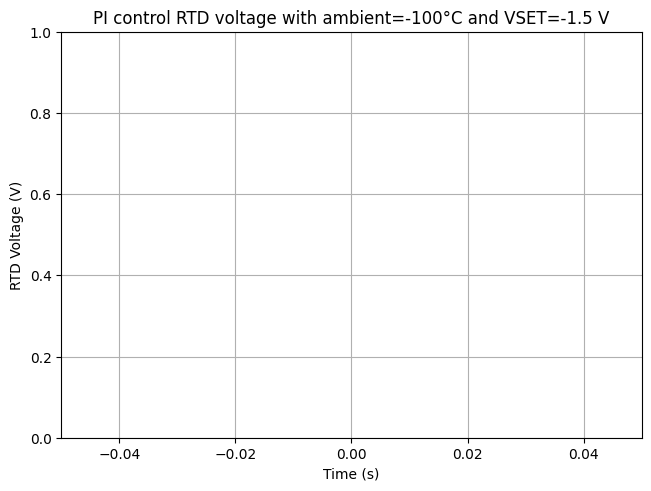

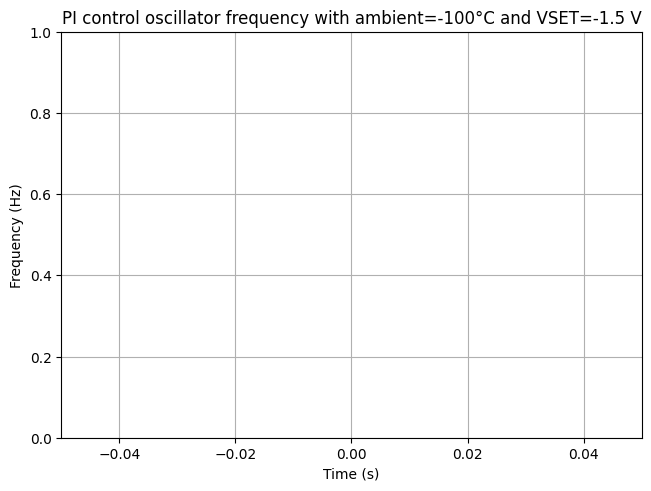

In [53]:
# Use this to print the formatting of all of your plots - not called during tests
# This is why plot initializations are separate

plot_amb_Ts = [-100]
plot_VSETs = [-1.5]

def initialize_all_plots(amb_Ts, VSETs):
    for amb_T in amb_Ts:
        for VSET in VSETs:
            fig, ax = heat_on_off_plot_VRTD_init(f"PI control RTD voltage with ambient={amb_T}°C and VSET={VSET} V", "Time (s)", f"RTD Voltage (V)")
            fig, ax = heat_on_off_plot_freq_init(f"PI control oscillator frequency with ambient={amb_T}°C and VSET={VSET} V", "Time (s)", f"Frequency (Hz)")
            pass # "pass" allows you to comment out the above line without python yelling at you for the loop doing nothing
    plt.show()

initialize_all_plots(plot_amb_Ts, plot_VSETs)

<h3>* Generate Experimental Plots </h3>

In [ ]:
execute_cells_by_tag('init') 

# Manual use - Not called during procedure

plot_amb_Ts = [-100]
plot_VSETs = [-0.924]

date = "2026-04-02" # Manually set 
run = "Single_Temp_2_[-100°C][Cold_Start][Heat_On_Off]" # Manually set
read_dir = os.path.join(f"{DEVICE_NAME}_Results", date, run, "Cold_Start") 
write_dir = os.path.join(f"{DEVICE_NAME}_Results", date, run, "Plots_Generated_Later") # Make sure this doesn't overwrite anything important

# dir = os.path.join("Combined_Data", "Combined_Experiment")
# read_dir = os.path.join(dir, "Combined_Temps")
# write_dir = os.path.join(dir, "Plots")
# os.makedirs(write_dir,exist_ok=True)

LOG = True
plot_all(read_dir, write_dir, plot_amb_Ts, plot_VSETs)

Imported Libraries
ICASL is loaded!
Initialized Constants:
RUN_TIME = 540
NUM_MEASUREMENTS_BEFORE_HEAT = 20
GLOBAL_VSET = -1.1
GLOBAL_TEMPS = [-25, -28, -30, -40, -50, -75, -100]
Initialized 'Establish Connection'
Initialized Equipment Interfacing Functions
Initialized Plotting Default Styling
Initialized Plotting Functions
Initialized Full Procedure


<h2> Running Experiment </h2>

<h3> Tests </h3>

In [ ]:
# Tests/Sweeps:

def run_tests(save_dir):
    # Comment out tests you don't want to run
    # You should only be running one of these two tests at a time
    
    heat_stays_on(save_dir)
    #heat_on_off(save_dir)

    measure_all_continuously() # Reactivates MMs

# Right now, assumes you have manually turned on the rails of the heat loop before running the test. Should already be at FZTC as well.
# Outer temperature sweep will simply sweep down from FZTC with heater on.
def heat_stays_on(save_dir):
    print("\nSTARTING TEST: heat stays on\n")
    time.sleep(1)

    ICASL.beep()
    time.sleep(30)

    # Measure
    temp = CHAMBER.query("USER?")
    VRTD = MM_VRTD.query(":READ?")
    V1mA = MM_V1mA.query(":READ?")
    freq = OSC_measure_freq(OSC_oscillator, 1)
    STD = OSC_measure_std(OSC_oscillator, 1)
    duty_cycle = OSC_measure_duty(OSC_tri_pulse, 4)
    VPP = OSC_measure_peak_to_peak(OSC_tri_pulse, 4)
    currents = [current.strip() for current in PS_read_all_current(PS_heat).split(',')]

    OSC_set_measurements(OSC_oscillator, 1) # Reset visually. 

    # Store data
    if LOG: print(f"Ran with heat staying on, storing")
    df = pd.DataFrame({'ambient_temp': [temp], 'VRTD': [VRTD], 'V1mA': [V1mA], 'frequency' : [freq], 'standard_deviation': [STD], 
                       'duty_cycle': [duty_cycle], 'pulse_height': [VPP], 'heat_IDD' : [currents[0]], 'heat_ISS' : [currents[1]]})  # Create a DataFrame
    store_data(df, save_dir, GLOBAL_VSET, "Heat_Stays_On")
    #df.to_csv(os.path.join(save_dir, f'Heat_Stays_On_Data_VSET={GLOBAL_VSET}.csv'), index=False)

# Heat on/off timing: heat is off for (MEASURE_TIME*NUM_MEASURE), turns on and stays on for RUN_TIME, turns off and stays off for RUN_TIME. Data saves.
def heat_on_off(save_dir):
    print("\nSTARTING TEST: heat on/off\n")
    time.sleep(1)
    # MAKE SURE TRIANGLE WAVE AND VSET ARE BOTH ON

    times = []
    heater_status_bits = []
    temps = []
    VRTDs = []
    V1mAs = []
    freqs = []
    #STDs = [] # Removed for faster communication
    duty_cycles = []
    VPPs = []
    heat_IDDs = []
    heat_ISSs = []
    start_time = time.perf_counter()
    current_time = 0
    measurements = 0
    heat_turned_off = False
    beeped = False
    IDLE_TIME = 40 # Will likely be overwritten
    heater_status = 0

    while (current_time < 2*RUN_TIME + IDLE_TIME):
        # Measure
        measurements = measurements+1
        current_time = time.perf_counter() - start_time
        temps.append(CHAMBER.query("USER?"))
        VRTDs.append(MM_VRTD.query(":READ?"))
        V1mAs.append(MM_V1mA.query(":READ?"))
        freqs.append(OSC_measure_freq(OSC_oscillator, 1))
        duty_cycles.append(OSC_measure_duty(OSC_tri_pulse, 4))
        VPPs.append(OSC_measure_peak_to_peak(OSC_tri_pulse, 4))
        currents = [current.strip() for current in PS_read_all_current(PS_heat).split(',')]
        heat_IDDs.append(currents[0])
        heat_ISSs.append(currents[1])
        heater_status_bits.append(heater_status)

        # OSC_set_measurements(OSC_oscillator, 1) # Reset visually. Will probably slow things down.
        times.append(current_time)
        if LOG: 
            new_current_time = time.perf_counter() - start_time
            #print(f"Started measuring at time {current_time}")
            print(f"Finished measuring at time {new_current_time}")

        # After this many measurements, heating is activated.
        if (measurements==NUM_MEASUREMENTS_BEFORE_HEAT):
            print(f"Turning on heat loop at time {current_time}")
            PS_turn_on(PS_heat)
            heater_status = 1
            if LOG: print(f"Heating turned ON!")
            IDLE_TIME = current_time 
        
        # After the first RUN_TIME passes, heating is deactivated for the duration of the second RUN_TIME
        if (current_time >= RUN_TIME+IDLE_TIME and heat_turned_off==False):
            print(f"Setting VSET to 0 at time {current_time}")
            PS_turn_off(PS_heat)
            heater_status = 0
            if LOG: print(f"Heating turned OFF!")
            heat_turned_off = True

        # Audio cue to manually record frequency counter -- happens 30 seconds before heating turns off
        if ((current_time >= RUN_TIME+IDLE_TIME-30) and not beeped):
            ICASL.beep()
            beeped = True

    OSC_set_measurements(OSC_oscillator, 1)

    # Store data
    if LOG: print(f"Finished running for time {RUN_TIME}, storing")
    df = pd.DataFrame({'time':times, "heater_status": heater_status_bits, "ambient_temp":temps, 'VRTD':VRTDs, 'V1mA':V1mAs, 'frequency':freqs, 
                       'duty_cycle':duty_cycles, 'pulse_height':VPPs, 'heat_IDD':heat_IDDs, 'heat_ISS':heat_ISSs}) # Create a dataframe
    store_data(df, save_dir, GLOBAL_VSET, "heat_on_off")

<h3> Temperature Sweeps </h3>

In [ ]:
#####################################################################################################################
################## IMPORTANT: Make sure all CHAMBER commands are contained with an if(USE_CHAMBER): #################
#####################################################################################################################

# USE_CHAMBER = True - turns on the temperature chamber and performs the temperature sweep
# USE_CHAMBER = False - performs a test run without interacting with the chamber.

def temperature_sweep(USE_CHAMBER, run_dir, local_temps, additional_temps_to_plot=[], do_cold_start=False):
    
    ################## Temperature Sweep ##################
         
    # This allows you to plot temperatures tested in previous runs. Make sure you're using the same "run_dir". 
    temps_tested = additional_temps_to_plot 

    for temp in local_temps:
        temp_dir = os.path.join(run_dir, f"temp={temp}") # The temperature of the experiment gets set as the sub-directory name
        os.makedirs(temp_dir, exist_ok=True) # Create a directory with the given name. If the directory already exists, it won't raise an error due to exist_ok=True

        ##### SET TEMPERATURE #####

        if (USE_CHAMBER): 
            CHAMBER.write(f"SET={temp}")
            if LOG: 
                print(f"Chamber status: {CHAMBER.query("STATUS?")}")
                print(f"Set chamber temperature to {temp}")
                start_time = time.perf_counter()
            wait = 0
            while(True):
                # Enters "Transition" state between temperatures
                user_probe_temp = CHAMBER.query("USER?")

                if (temp < -165 and user_probe_temp < -155):  # If low and dropping lower
                    CHAMBER.write("RATE=10")                  # Slow chamber's rate of change. Seems to reduce LN2 spillage.
                    CHAMBER.write("HOFF")                     # Stops chamber from heating when approaching -175; it can be stupid sometimes.
                
                # Every 10 seconds, updates
                WAIT_TIME = 10
                time.sleep(WAIT_TIME)
                print(f"Time is {time.perf_counter()-start_time}")

                # Probe must stay within a set range of the desired temp for the duration of the SOAK_TIME. 
                if (temp+SET_PRECISION >= float(user_probe_temp) >= temp-SET_PRECISION):
                    if LOG and (wait==1): print(f"Soak time starting at time {time.perf_counter() - start_time} since user probe read {user_probe_temp}")
                    wait = wait + 1
                else:
                    if LOG and (wait!=0): print(f"Soak time canceled at time {time.perf_counter() - start_time} since user probe read {user_probe_temp}")
                    wait = 0
                if (wait-1)*WAIT_TIME >= SOAK_TIME:
                    if LOG: print(f"Soak time of {SOAK_TIME} seconds completed at time {time.perf_counter() - start_time}. User probe reads {user_probe_temp}")
                    break
            if LOG: print(f"After reaching {temp}°C, chamber status is: {CHAMBER.query("STATUS?")}")

        # Tests
        print(f"Performing tests at temp {temp}") # No LOG required
        run_tests(temp_dir)
        if LOG: print("Finished all tests")
        measure_all_continuously() # Sets multimeters to continuously read after tests are done

        # Update directory name
        # TODO: Check if there's actually data inside before renaming
        rename = ICASL.remove_attribute(run_dir, "No_Data") # The directory containing this has the attribute "[No_Data]" removed.
        if rename != None and isinstance(rename, str):
            # Resets "run_dir" and "temp_dir" to match new name (with attribute removed)
            run_dir = rename
            temp_dir = os.path.join(run_dir, f"temp={temp}") # The temperature of the experiment gets set as the sub-directory name
            time.sleep(3)
        
        # Plots
        temps_tested.append(temp)
        plot_all(run_dir, temp_dir, temps_tested, [GLOBAL_VSET]) # Intermediate plots. Runs each temperature, shows all so far. 
    
    # Overall plots
    print("Finished temperature sweep.\nPlotting")
    FINAL_PLOTS_DIR = os.path.join(run_dir, "Final_Plots")
    os.makedirs(FINAL_PLOTS_DIR, exist_ok=True)
    plot_all(run_dir, FINAL_PLOTS_DIR, local_temps, [GLOBAL_VSET])
    # TODO: If final_plots folder is empty after plotting, add an [empty] attribute to it.

    if (USE_CHAMBER and do_cold_start):
        cold_start(temps_tested[-1], run_dir)

# For this particular test, the power supplies will not be turned off. You must do so manually.
def cold_start(temp, run_dir):
    #Unless all power supplies are connected, you probably need to do this part manually
    turn_off_all()               # Turn off voltages 
    time.sleep(COLD_START_TIME)  # Wait for device to cool
    turn_on_all()

    # Cold start data is stored in a subdirectory. This means it is ignored by default by plotting functions but can be
    # parsed identically by simply passing this subdirectory to those functions rather than the higher directory
    run_dir_CS = os.path.join(run_dir, "Cold_Start")
    temp_dir_CS = os.path.join(run_dir_CS, f"temp={temp}")
    os.makedirs(temp_dir_CS, exist_ok=True)
    
    run_tests(temp_dir_CS)   
    plot_all(run_dir_CS, temp_dir_CS, [temp], [GLOBAL_VSET])


print("Initialized Full Procedure")

Initialized Full Procedure


Inputs for Running Experiment

In [102]:
measure_all()

Multimeter VRTD: +3.54651967E-05
Multimeter V1mA: -5.67697514E-06
Power Supply Heat Loop currents: 0, 0, 0


In [57]:
# DO NOT RUN WITH OUTPUT OFF
measure_all_continuously()

In [ ]:
# GLOBAL_VSET = VSET_ROOM_TEMP
# WG_on(WG_VSET, 1, GLOBAL_VSET)

In [ ]:
# GLOBAL_VSET = VSET_FZTC
# initialize_all()
# WG_on(WG_VSET, 1, GLOBAL_VSET)

WG_VSET set to -0.924
Power supply is currently OFF
The channels are set to:
Channel 1: 5, 0.75
Channel 2: 5, 0.75
Channel 3: 0, 0.01


### * Single Temp. Run

In [ ]:
execute_cells_by_tag('init')
# PRACTICE Run, chamber not affected.
# Runs all of the "temperature sweep" code without actually touching the temperature. Good for running at a single temp.

#### INPUTS ####

single_temp = [-100]        # SET EVERY TIME. For file labeling purposes, doesn't actually set the temp.
GLOBAL_VSET = VSET_FZTC     # SET EVERY TIME
info = f""        # SET EVERY TIME
# Check the "Constants" section too!

#### EQUIPMENT INITIALIZATION ####

#initialize_all() # This may set VSET to 0 for a few milliseconds. Won't turn heat loop on. Doesn't interface with chamber.

#### RUN EXPERIMENT ####

run_dir = ICASL.generate_experiment_name("Single_Temp", single_temp, DEVICE_NAME, info) # Create file path
if LOG: print(f"Run directory is {run_dir}")
temperature_sweep(False, run_dir, local_temps=single_temp)
#cold_start(-100, run_dir)
ICASL.beep()

Imported Libraries
ICASL is loaded!
Initialized Constants:
RUN_TIME = 540
NUM_MEASUREMENTS_BEFORE_HEAT = 20
GLOBAL_VSET = -1.1
GLOBAL_TEMPS = [-25, -28, -30, -40, -50, -75, -100]
Initialized 'Establish Connection'
Initialized Equipment Interfacing Functions
Initialized Plotting Default Styling
Initialized Plotting Functions
Initialized Full Procedure
Run directory is Prototype_Board_Results\2026-04-02\Single_Temp_2_[-100°C][No_Data][Cold_Start][Heat_On_Off]

STARTING TEST: heat on/off

Finished measuring at time 0.8924373998306692
Finished measuring at time 1.40789489983581
Finished measuring at time 1.9562867998611182
Finished measuring at time 2.422153899911791
Finished measuring at time 2.903876599855721
Finished measuring at time 3.620076899882406
Finished measuring at time 4.11895709997043
Finished measuring at time 4.618412199895829
Finished measuring at time 5.083728599827737
Finished measuring at time 5.732664099894464
Finished measuring at time 6.2312243999913335
Finished meas

### * Multi Temp. Run

In [60]:
execute_cells_by_tag('init')
# ACTUAL Run, chamber sweeps temperature

#### INPUTS ####

local_temps = [-28, -40, -50, -75, -100]     # Can change this to any list of temps. Ex: [0, 27, 50]. Runs in order.
#local_temps = [35]                              # SET EVERY TIME
GLOBAL_VSET = VSET_FZTC                    # SET EVERY TIME
info = f"Repeating_-28C"   # SET EVERY TIME
# Check the "Constants" section too!

#### EQUIPMENT INITIALIZATION ####

#initialize_all() # This may set VSET to 0 for a few milliseconds. Will then update it to GLOBAL_VSET.
chamber_init(RATE=20)

#### RUN EXPERIMENT ####

print(f"Testing these temperatures: {local_temps}")
run_dir = ICASL.generate_experiment_name("Temperature_Sweep", local_temps, DEVICE_NAME, info) # Create file path
if LOG: print(f"Run directory is {run_dir}")

# CHAMBER IS USED # CHAMBER IS USED # CHAMBER IS USED
temperature_sweep(USE_CHAMBER=True, run_dir=run_dir, local_temps=local_temps) 
# CHAMBER IS USED # CHAMBER IS USED # CHAMBER IS USED

ICASL.beep()

Imported Libraries
ICASL is loaded!
Initialized Constants:
RUN_TIME = 540
NUM_MEASUREMENTS_BEFORE_HEAT = 20
GLOBAL_VSET = -1.1
GLOBAL_TEMPS = [-25, -28, -30, -40, -50, -75, -100]
Initialized 'Establish Connection'
Initialized Equipment Interfacing Functions
Initialized Plotting Default Styling
Initialized Plotting Functions
Initialized Full Procedure
Testing these temperatures: [-28, -40, -50, -75, -100]
Run directory is Prototype_Board_Results\2026-04-02\Temperature_Sweep_2_[No_Data][Repeating_-28C]
Chamber status: YNNNYYYYYNNNNNNNNN0
Set chamber temperature to -28
Time is 10.012541000032797
Time is 20.125805200077593
Time is 30.192315299995244
Time is 40.20397990010679
Time is 50.21655730018392
Time is 60.231304300017655
Time is 70.25118600018322
Time is 80.26467579999007
Time is 90.27730890014209
Time is 100.28901290008798
Time is 110.30190070020035
Time is 120.31535020004958
Time is 130.3280896001961
Time is 140.34090680000372
Time is 150.35286450013518
Time is 160.3670605001971
Ti

Continue Experiment

In [59]:
# Run this cell for output that's close to what you need for temps_tested - might need to remove a temp that wasn't fully tested

sweep_variable_name = "temp"
old_dir = os.path.join(f"{DEVICE_NAME}_Results", "2026-04-02", "Temperature_Sweep_1_[Heat Stays On]") # Copy/paste in the previous experiment's directory name
print(ICASL.read_dir_values(old_dir, sweep_variable_name))

[-40, -30, -28, -25]


In [ ]:
execute_cells_by_tag('init')
# SET UP AND RUN PREVIOUS CELL FIRST

# Continue an existing ACTUAL Run, chamber sweeps temperature
# If you have to stop an experiment midway, use this to pick up right where you left off.

#### INPUTS ####

temps_tested = [-25, -28, -30]             # SET EVERY TIME -- Enter temps to not test at, but still use during plotting.
local_temps = []              # SET EVERY TIME
GLOBAL_VSET = VSET_ROOM_TEMP    # SET EVERY TIME
info = f""                      # SET EVERY TIME
# Check the "Constants" section too!

#### EQUIPMENT INITIALIZATION ####

#initialize_all() # This may set VSET to 0 for a few milliseconds 
chamber_init(RATE=20)

#### RUN ####

local_temps = [temp for temp in local_temps if temp not in temps_tested]
print(local_temps)

if (old_dir == "" or temps_tested == []): raise ValueError("Don't use this without an old_dir and temps_tested")
execute_cells_by_tag('init') 
run_dir = ICASL.generate_experiment_name("Experiment", local_temps, DEVICE_NAME, info)
if LOG: print(f"Run directory is {run_dir}")

# Copies old_dir contents to run_dir
import shutil
for item in os.listdir(old_dir):
    absolute_source_item = os.path.join(old_dir, item)
    relative_source_item = os.path.basename(absolute_source_item)
    num = ICASL.parse_num_from_string(relative_source_item, sweep_variable_name)
    if (num != None and num not in temps_tested):
        # Don't copy over temp folders that weren't mentioned in temps_tested
        continue
    else:
        destination_item = os.path.join(run_dir, item)
        if os.path.isdir(absolute_source_item): 
            shutil.copytree(absolute_source_item, destination_item, dirs_exist_ok=True)
        else:
            shutil.copy2(absolute_source_item, destination_item)

# CHAMBER IS USED # CHAMBER IS USED # CHAMBER IS USED # CHAMBER IS USED # CHAMBER IS USED
temperature_sweep(True, run_dir, local_temps=local_temps, additional_temps_to_plot=temps_tested) # CHAMBER IS USED
# CHAMBER IS USED # CHAMBER IS USED # CHAMBER IS USED# CHAMBER IS USED# CHAMBER IS USED

ICASL.beep()

Imported Libraries
ICASL is loaded!
Initialized Constants:
RUN_TIME = 60
NUM_MEASUREMENTS_BEFORE_HEAT = 10
GLOBAL_VSET = -1.1
GLOBAL_TEMPS = [-25, -28, -30, -40, -50, -75, -100]
Initialized 'Establish Connection'
Initialized Equipment Interfacing Functions
Initialized Plotting Default Styling
Initialized Plotting Functions
Initialized Full Procedure
WG_VSET set to -1.1
0
Power supply is currently OFF
The channels are set to:
Channel 1: 5, 0.75
Channel 2: 5, 0.75
Channel 3: 0, 0.01
[35]
Imported Libraries
ICASL is loaded!
Initialized Constants:
RUN_TIME = 60
NUM_MEASUREMENTS_BEFORE_HEAT = 10
GLOBAL_VSET = -1.1
GLOBAL_TEMPS = [-25, -28, -30, -40, -50, -75, -100]
Initialized 'Establish Connection'
Initialized Equipment Interfacing Functions
Initialized Plotting Default Styling
Initialized Plotting Functions
Initialized Full Procedure
Run directory is Prototype_Board_Results\2026-04-01\Experiment_3_[35°C][No_Data]
Chamber status:
YNNNYYYNYNNNNNNNNN0
Set chamber temperature to 35
Soak time 

Return Chamber to Room Temperature

In [6]:
# Return to room temperature
# TURN VALVE AND WAIT FIRST
CHAMBER.write("HON")
CHAMBER.write("COFF")
CHAMBER.write("RATE=20")
CHAMBER.write("SET=25")

7